**Libraries**

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

**checking categorical data**

In [9]:
# Install the Excel dependency required by pandas.read_excel() for .xlsx files
!pip install openpyxl

# Load the encoded survey workbook
c_df = pd.read_excel(
    r"C:\Users\laika\OneDrive\Documents\data4380\tabular project\MentalHealthSurvey - Encoded.xlsx",
    engine="openpyxl"
)
c_df.shape

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]



(83, 29)

In [10]:
# drop ordinal data
c_df = c_df.loc[:, ~c_df.columns.isin([
    'study_satisfaction', 'academic_workload ', 'academic_pressure', 
    'financial_concerns', 'social_relationships', 'depression', 
    'anxiety', 'isolation', 'future_insecurity'
])]

**Dataset**


In [11]:
df=pd.read_csv('MentalHealthSurvey.csv')
df.head(5)

,gender,age,university,degree_level,degree_major,academic_year,cgpa,residential_status,campus_discrimination,sports_engagement,...,study_satisfaction,academic_workload,academic_pressure,financial_concerns,social_relationships,depression,anxiety,isolation,future_insecurity,stress_relief_activities
0,Male,20,PU,Undergraduate,Data Science,2nd year,3.0-3.5,Off-Campus,No,No Sports,...,5,4,5,4,3,2,1,1,2,"Religious Activities, Social Connections, Onli..."
1,Male,20,UET,Postgraduate,Computer Science,3rd year,3.0-3.5,Off-Campus,No,1-3 times,...,5,4,4,1,3,3,3,3,4,Online Entertainment
2,Male,20,FAST,Undergraduate,Computer Science,3rd year,2.5-3.0,Off-Campus,No,1-3 times,...,5,5,5,3,4,2,3,3,1,"Religious Activities, Sports and Fitness, Onli..."
3,Male,20,UET,Undergraduate,Computer Science,3rd year,2.5-3.0,On-Campus,No,No Sports,...,3,5,4,4,1,5,5,5,3,Online Entertainment
4,Female,20,UET,Undergraduate,Computer Science,3rd year,3.0-3.5,Off-Campus,Yes,No Sports,...,3,5,5,2,3,5,5,4,4,Online Entertainment


In [12]:
# Shape
print(f'Dataset Shape:',df.shape)
print('\n')
# Data types
print('Data types:')
print(df.dtypes)

Dataset Shape: (87, 21)


Data types:
gender                      object
age                          int64
university                  object
degree_level                object
degree_major                object
academic_year               object
cgpa                        object
residential_status          object
campus_discrimination       object
sports_engagement           object
average_sleep               object
study_satisfaction           int64
academic_workload            int64
academic_pressure            int64
financial_concerns           int64
social_relationships         int64
depression                   int64
anxiety                      int64
isolation                    int64
future_insecurity            int64
stress_relief_activities    object
dtype: object


**Data Cleaning**


In [13]:
# Remove age outliers (26)
df_clean=df[df['age']!=26]

# Remove postgraduate students
df_clean=df_clean[df_clean['degree_level']!='Postgraduate']

# Remove students with no stress relief activity
df_clean=df_clean[df_clean['stress_relief_activities']!='Nothing']

# Drop age column
df_clean=df_clean.drop(columns=['age'])

print('Clean Dataset Shape:', df_clean.shape)

display(df_clean.head(5))

Clean Dataset Shape: (83, 20)


,gender,university,degree_level,degree_major,academic_year,cgpa,residential_status,campus_discrimination,sports_engagement,average_sleep,study_satisfaction,academic_workload,academic_pressure,financial_concerns,social_relationships,depression,anxiety,isolation,future_insecurity,stress_relief_activities
0,Male,PU,Undergraduate,Data Science,2nd year,3.0-3.5,Off-Campus,No,No Sports,4-6 hrs,5,4,5,4,3,2,1,1,2,"Religious Activities, Social Connections, Onli..."
2,Male,FAST,Undergraduate,Computer Science,3rd year,2.5-3.0,Off-Campus,No,1-3 times,2-4 hrs,5,5,5,3,4,2,3,3,1,"Religious Activities, Sports and Fitness, Onli..."
3,Male,UET,Undergraduate,Computer Science,3rd year,2.5-3.0,On-Campus,No,No Sports,4-6 hrs,3,5,4,4,1,5,5,5,3,Online Entertainment
4,Female,UET,Undergraduate,Computer Science,3rd year,3.0-3.5,Off-Campus,Yes,No Sports,4-6 hrs,3,5,5,2,3,5,5,4,4,Online Entertainment
5,Female,UET,Undergraduate,Computer Science,3rd year,3.0-3.5,Off-Campus,No,No Sports,4-6 hrs,4,5,5,3,3,5,5,5,5,"Religious Activities, Social Connections, Onli..."


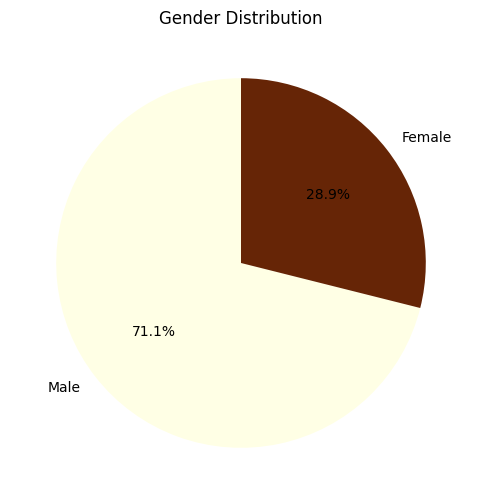

In [14]:

# Calculate percentages
gender_percentages = df_clean['gender'].value_counts(normalize=True) * 100

# Create the pie chart
plt.figure(figsize=(6, 6))
gender_percentages.plot(kind='pie', autopct='%1.1f%%', startangle=90, cmap='YlOrBr')

plt.title('Gender Distribution')
plt.ylabel('') # Removes the default y-axis label for a cleaner look
plt.show()

In [15]:
gender_counts = df_clean['gender'].value_counts()
display(gender_counts)

gender
Male      59
Female    24
Name: count, dtype: int64

In [16]:
# Split dataset to include only ordinal values
numeric_df=df_clean.select_dtypes(include=np.number)

display(numeric_df.head(5))

,study_satisfaction,academic_workload,academic_pressure,financial_concerns,social_relationships,depression,anxiety,isolation,future_insecurity
0,5,4,5,4,3,2,1,1,2
2,5,5,5,3,4,2,3,3,1
3,3,5,4,4,1,5,5,5,3
4,3,5,5,2,3,5,5,4,4
5,4,5,5,3,3,5,5,5,5


**Visualizations For Ordinal Features**

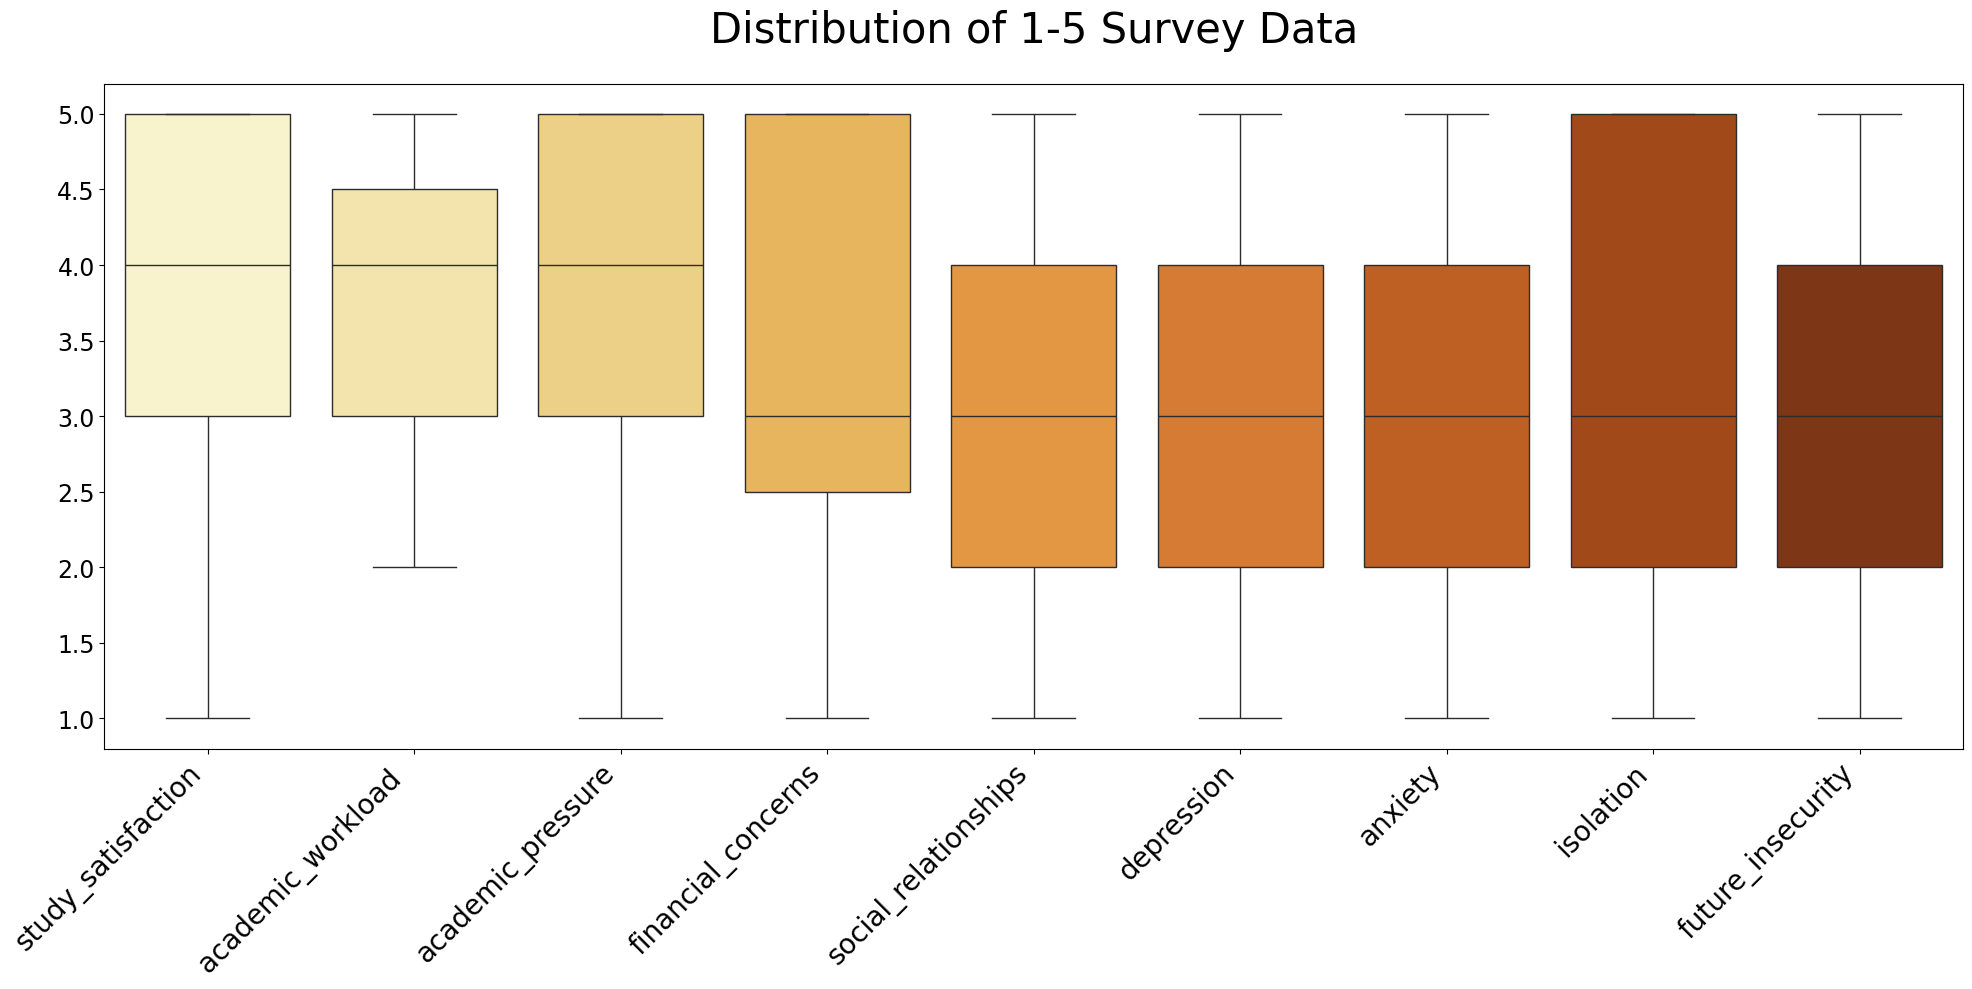

In [17]:
# Boxplot
plt.figure(figsize=(20,10))
sns.boxplot(data=numeric_df, palette='YlOrBr')
plt.title('Distribution of 1-5 Survey Data', fontsize=30, pad=30)
plt.xticks(rotation=45, ha='right', fontsize=20)
plt.yticks(fontsize=17)
plt.tight_layout()
plt.show()


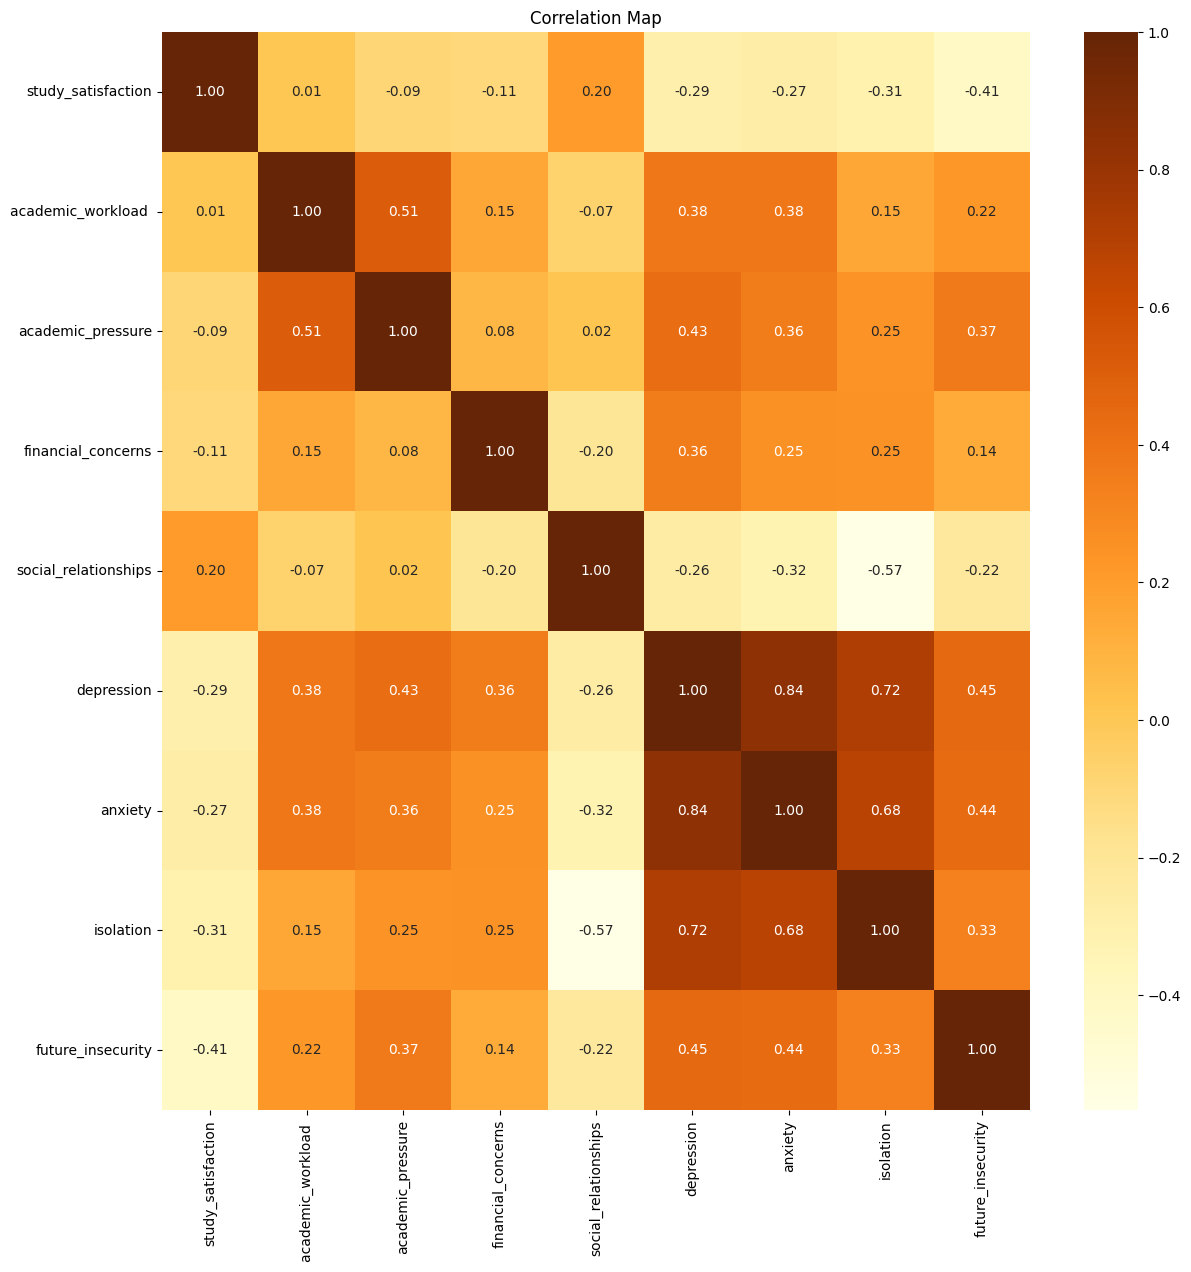

In [18]:
# Correlation map
plt.figure(figsize=(14, 14))
sns.heatmap(numeric_df.corr(), annot=True, cmap='YlOrBr', fmt=".2f")
plt.title("Correlation Map")
plt.show()

**Scaling**

In [19]:
# min max scaling
scaler=MinMaxScaler()
scaled_df=scaler.fit_transform(numeric_df)

# back to dataframe
scaled_df=pd.DataFrame(scaled_df, columns=numeric_df.columns, index=numeric_df.index)

print(f'Shape of preprocessed ordinal data:', scaled_df.shape)
display(scaled_df.head(5))


Shape of preprocessed ordinal data: (83, 9)


,study_satisfaction,academic_workload,academic_pressure,financial_concerns,social_relationships,depression,anxiety,isolation,future_insecurity
0,1.00,0.666667,1.00,0.75,0.50,0.25,0.0,0.00,0.25
2,1.00,1.000000,1.00,0.50,0.75,0.25,0.5,0.50,0.00
3,0.50,1.000000,0.75,0.75,0.00,1.00,1.0,1.00,0.50
4,0.50,1.000000,1.00,0.25,0.50,1.00,1.0,0.75,0.75
5,0.75,1.000000,1.00,0.50,0.50,1.00,1.0,1.00,1.00


**Total Dataset After Preprocessing**

In [20]:
# reset indexes
scaled_df=scaled_df.reset_index(drop=True)
c_df=c_df.reset_index(drop=True)

# combine categorical and ordinal features
total_preprocessing=pd.concat([c_df, scaled_df], axis=1)

print(f'Total Preprocessing Shape:', total_preprocessing.shape)
display(total_preprocessing.head(5))

Total Preprocessing Shape: (83, 29)


,student_id,academic_year,cgpa,residential_status,campus_discrimination,sports_engagement,average_sleep,degree_major_Computer Science,degree_major_Data Science,degree_major_Information Technology,...,activity_Sports and Fitness,study_satisfaction,academic_workload,academic_pressure,financial_concerns,social_relationships,depression,anxiety,isolation,future_insecurity
0,1888,1,4,0,0,0,1,0,1,0,...,0,1.00,0.666667,1.00,0.75,0.50,0.25,0.0,0.00,0.25
1,6958,2,3,0,0,1,0,1,0,0,...,1,1.00,1.000000,1.00,0.50,0.75,0.25,0.5,0.50,0.00
2,3742,2,3,1,0,0,1,1,0,0,...,0,0.50,1.000000,0.75,0.75,0.00,1.00,1.0,1.00,0.50
3,2065,2,4,0,1,0,1,1,0,0,...,0,0.50,1.000000,1.00,0.25,0.50,1.00,1.0,0.75,0.75
4,8645,2,4,0,0,0,1,1,0,0,...,0,0.75,1.000000,1.00,0.50,0.50,1.00,1.0,1.00,1.00


In [21]:
# drop student id
total_preprocessing=total_preprocessing.drop(columns=['student_id'])

print(f'Total Preprocessing Shape:', total_preprocessing.shape)
display(total_preprocessing.head(5))

Total Preprocessing Shape: (83, 28)


,academic_year,cgpa,residential_status,campus_discrimination,sports_engagement,average_sleep,degree_major_Computer Science,degree_major_Data Science,degree_major_Information Technology,degree_major_Software Engineering,...,activity_Sports and Fitness,study_satisfaction,academic_workload,academic_pressure,financial_concerns,social_relationships,depression,anxiety,isolation,future_insecurity
0,1,4,0,0,0,1,0,1,0,0,...,0,1.00,0.666667,1.00,0.75,0.50,0.25,0.0,0.00,0.25
1,2,3,0,0,1,0,1,0,0,0,...,1,1.00,1.000000,1.00,0.50,0.75,0.25,0.5,0.50,0.00
2,2,3,1,0,0,1,1,0,0,0,...,0,0.50,1.000000,0.75,0.75,0.00,1.00,1.0,1.00,0.50
3,2,4,0,1,0,1,1,0,0,0,...,0,0.50,1.000000,1.00,0.25,0.50,1.00,1.0,0.75,0.75
4,2,4,0,0,0,1,1,0,0,0,...,0,0.75,1.000000,1.00,0.50,0.50,1.00,1.0,1.00,1.00


In [22]:
# checking for duplicate values that may appear since I pulled from the original dataset
print(total_preprocessing.columns.duplicated())


[False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False]


**Export total_preprocessing**

In [23]:
total_preprocessing.to_csv('mental_health_preprocessed.csv', index=False)